# Chest X-ray 肺炎分類 — 探索性資料分析（EDA）

對應報告大綱 `docs/agenda.md` 的**第一章（資料集介紹）**與**第二章（資料前處理與探索性分析）**。

模組都在 repo 的 `.py` 裡，這本 notebook 只負責把它們串起來——與
`efficient_train.ipynb` 同一個慣例，不要把函式定義貼回這裡。

這本與訓練無關：不建模型、不跑 GPU，只讀影像檔頭做統計。
產物固定寫到 `../outputs/eda/`（不帶時間戳），重跑就覆蓋同一份。

| Cell | 做什麼 | agenda |
| --- | --- | --- |
| 1 | 匯入模組 | — |
| 2 | **設定（改參數只改這裡）** | — |
| 3 | 下載資料與清點 | 1-2 樣本規模 |
| 4 | 原始切分的類別分佈 | 1-3 官方 val 僅 16 張 |
| 5 | 掃描影像尺寸與色彩模式 | 2-1 混雜狀況（數字）|
| 6 | 尺寸與長寬比分布圖 | 2-1 混雜狀況（圖）|
| 7 | 色彩模式分布 | 2-1 色彩模式 |
| 8 | 樣本影像與標準化前後對照 | 2-1 標準化策略 |
| 9 | 重新切分 70/15/15 的類別分佈 | 2-2 不平衡、2-3 切分 |
| 10 | 儲存 EDA 產物 | — |

Kaggle 憑證放 `~/.kaggle/kaggle.json`，或設 `KAGGLE_USERNAME` / `KAGGLE_KEY` 環境變數。

In [10]:
# Cell 1 — 匯入模組
import sys

sys.path.insert(0, "..")
%matplotlib inline

from data.dataset import download_dataset
from data.eda import mode_counts, size_summary, survey_images
from data.split import (
    collect_all_images,
    count_images,
    group_counts,
    patient_group_key,
    plan_splits,
    split_counts,
)
from engine.visualize import (
    plot_aspect_hist,
    plot_class_distribution,
    plot_sample_grid,
    plot_size_scatter,
    plot_transform_comparison,
)
from env import collect_run_info
from utils import make_output_dir, save_eda_results

run_info = collect_run_info()
print(f"程式碼版本 git_commit: {run_info['git_commit']}")

程式碼版本 git_commit: 037967183f1eb97c71e9a2e9251e0aef3442dde6


In [11]:
# Cell 2 — 設定（只改這個 cell）
# 要與訓練用的切分一致，這三個值必須跟 efficient_train.ipynb 相同
SPLIT_SEED          = 42
TRAIN_RATIO         = 0.70
VAL_RATIO           = 0.15
TEST_RATIO          = 0.15
GROUP_BY_PATIENT    = True

# 前後對照圖要用的尺寸，對齊訓練設定
IMAGE_SIZE          = 224

# 抽樣張數與抽樣種子，固定才重現得了同一張圖
SAMPLES_PER_CLASS   = 4
SAMPLE_SEED         = 0

OUTPUT_BASE         = "../outputs"
DATASET_LOCAL_DIR   = None

print(f"SPLIT_SEED={SPLIT_SEED}  GROUP_BY_PATIENT={GROUP_BY_PATIENT}")

SPLIT_SEED=42  GROUP_BY_PATIENT=True


In [12]:
# Cell 3 — 下載資料與清點
raw_root = download_dataset(local_dir=DATASET_LOCAL_DIR)
print(f"資料集路徑: {raw_root}\n")

counts = count_images(raw_root)
for split, per_class in counts.items():
    total = sum(per_class.values())
    print(f"{split:<5} {per_class}  (共 {total})")

grand_total = sum(sum(c.values()) for c in counts.values())
print(f"\n總張數: {grand_total}")

Kaggle 憑證來源：~/.kaggle/kaggle.json
kagglehub 快取路徑：C:\Users\Edward\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2
資料集路徑: C:\Users\Edward\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2\chest_xray

train {'NORMAL': 1341, 'PNEUMONIA': 3875}  (共 5216)
val   {'NORMAL': 8, 'PNEUMONIA': 8}  (共 16)
test  {'NORMAL': 234, 'PNEUMONIA': 390}  (共 624)

總張數: 5856


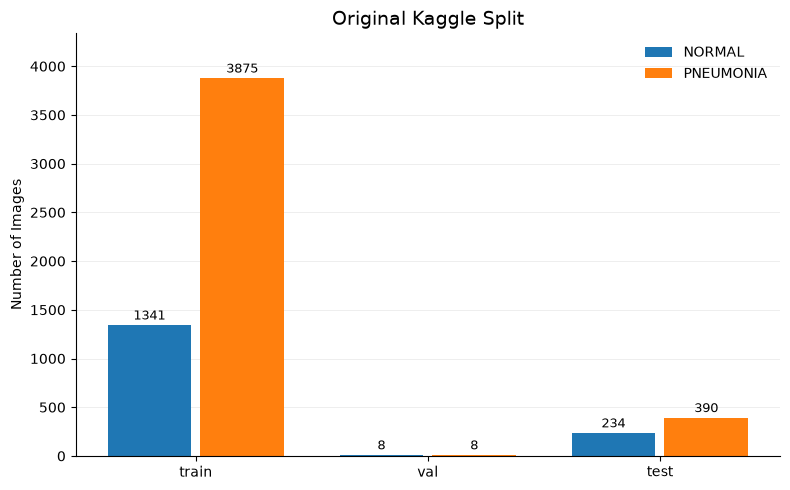

In [13]:
# Cell 4 — 原始切分的類別分佈
# 官方 val 只有 16 張，太少
fig_original = plot_class_distribution(counts, title="Original Kaggle Split", show=True)

In [14]:
# Cell 5 — 掃描影像尺寸與色彩模式
# 只讀檔頭不解碼像素
all_images = collect_all_images(raw_root)
survey = survey_images(all_images)

sizes = size_summary(survey)
modes = mode_counts(survey)

for class_name, stat in sizes.items():
    print(f"[{class_name}] n={stat['count']}  相異尺寸={stat['unique_sizes']}")
    for key in ("width", "height", "aspect"):
        d = stat[key]
        # 長寬比是小數，不能跟像素一樣取整
        fmt = ".2f" if key == "aspect" else ".0f"
        print(
            f"  {key:<7} min={d['min']:{fmt}}  max={d['max']:{fmt}}  "
            f"median={d['median']:.2f}  mean={d['mean']:.2f}"
        )

print(f"\n色彩模式: {modes}")

[NORMAL] n=1583  相異尺寸=1563
  width   min=912  max=2916  median=1654.00  mean=1686.38
  height  min=496  max=2713  median=1323.00  mean=1378.65
  aspect  min=0.88  max=2.11  median=1.23  mean=1.25
[PNEUMONIA] n=4273  相異尺寸=3272
  width   min=384  max=2772  median=1160.00  mean=1195.07
  height  min=127  max=2304  median=776.00  mean=819.55
  aspect  min=0.84  max=3.38  median=1.49  mean=1.51

色彩模式: {'NORMAL': {'L': 1583}, 'PNEUMONIA': {'L': 3990, 'RGB': 283}}


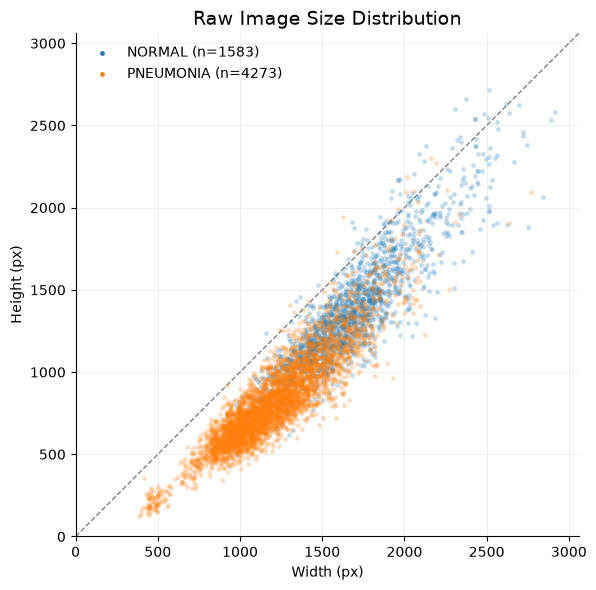

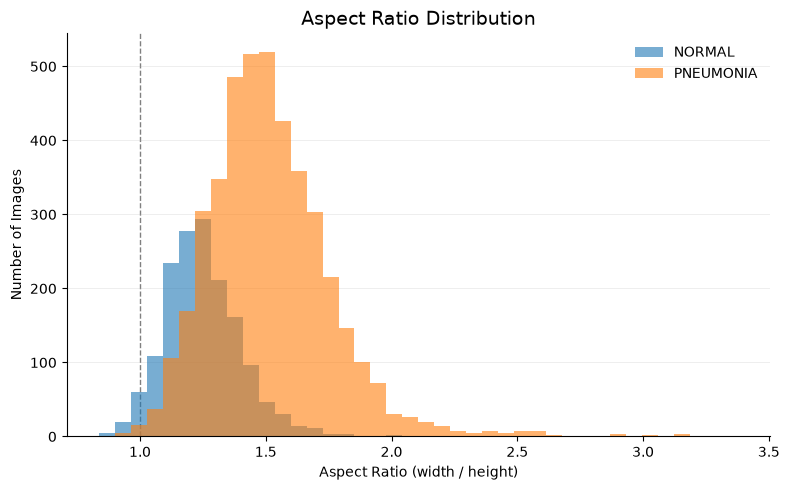

In [15]:
# Cell 6 — 尺寸與長寬比分布
fig_scatter = plot_size_scatter(survey, show=True)
fig_aspect = plot_aspect_hist(survey, show=True)

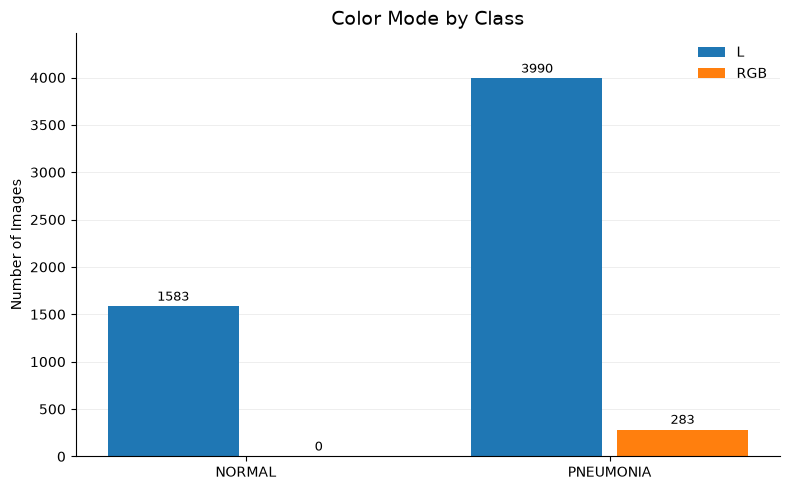

In [16]:
# Cell 7 — 色彩模式分布
# mode_counts 的形狀與 counts 相同，直接重用同一個繪圖函式
fig_modes = plot_class_distribution(modes, title="Color Mode by Class", show=True)

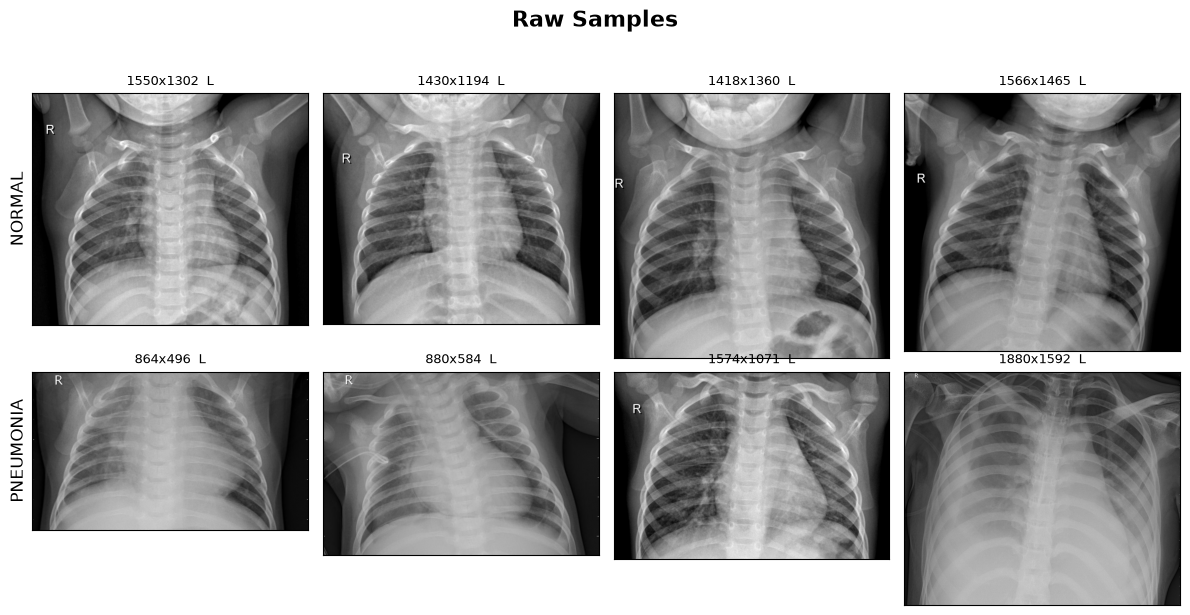

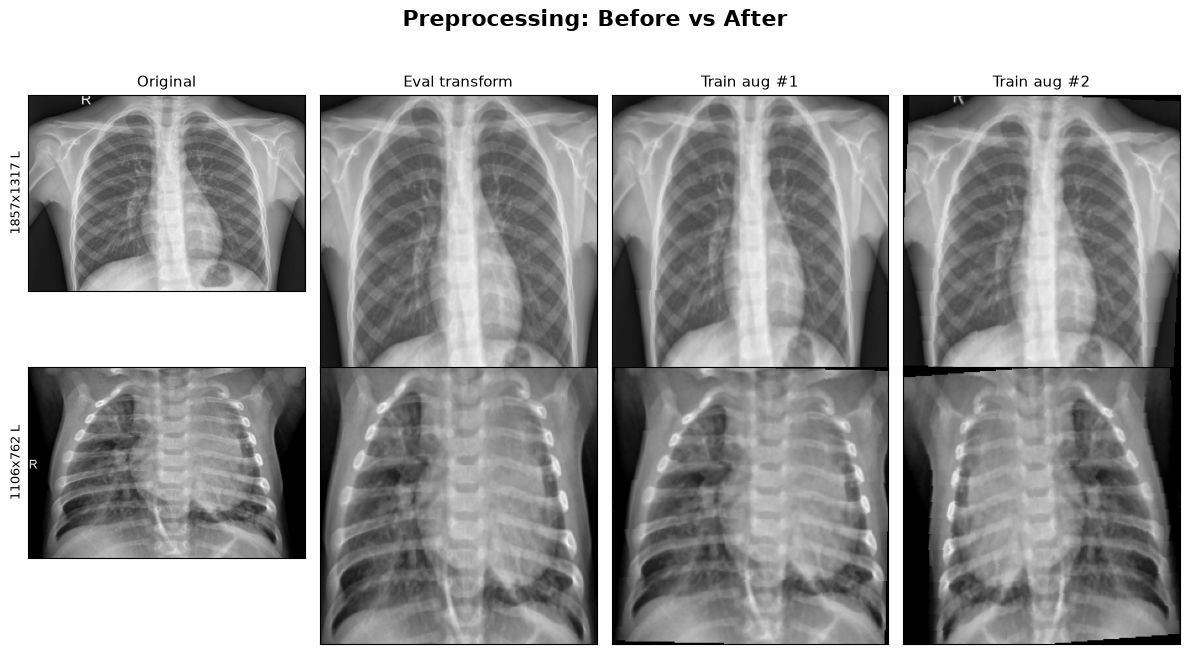

In [17]:
# Cell 8 — 樣本影像與標準化前後對照
fig_samples = plot_sample_grid(
    survey, n_per_class=SAMPLES_PER_CLASS, seed=SAMPLE_SEED, show=True
)

# 每類取第一張看 transform 的效果
# 這份清單等一下原樣傳給 save_eda_results，存檔的圖才跟這裡看到的一致
sample_paths = [records[0]["path"] for records in survey.values()]
fig_transform = plot_transform_comparison(
    sample_paths, img_size=IMAGE_SIZE, seed=SAMPLE_SEED, show=True
)

群組數: {'NORMAL': 1583, 'PNEUMONIA': 1844}
張數  : {'NORMAL': 1583, 'PNEUMONIA': 4273}
train {'NORMAL': 1108, 'PNEUMONIA': 2991}  (共 4099, PNEUMONIA:NORMAL = 2.70:1)
val   {'NORMAL': 238, 'PNEUMONIA': 641}  (共 879, PNEUMONIA:NORMAL = 2.69:1)
test  {'NORMAL': 237, 'PNEUMONIA': 641}  (共 878, PNEUMONIA:NORMAL = 2.70:1)


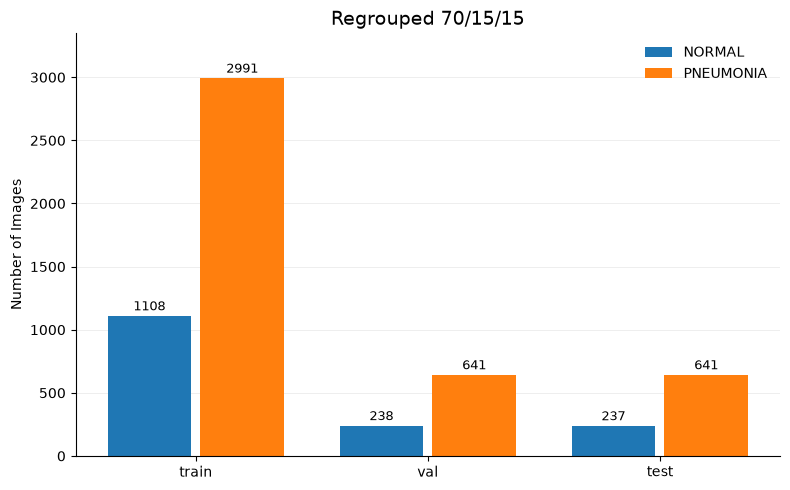

In [18]:
# Cell 9 — 重新切分 70/15/15 的類別分佈
group_key = patient_group_key if GROUP_BY_PATIENT else None
if group_key is not None:
    # 群組數等於張數表示沒分組
    stats_groups = group_counts(all_images, group_key)
    print("群組數:", stats_groups)
    print("張數  :", {c: len(v) for c, v in all_images.items()})
else:
    stats_groups = None

plan = plan_splits(
    all_images,
    split_seed=SPLIT_SEED,
    train_ratio=TRAIN_RATIO,
    val_ratio=VAL_RATIO,
    test_ratio=TEST_RATIO,
    group_key=group_key,
)

counts_after = split_counts(plan)
for split, per_class in counts_after.items():
    total = sum(per_class.values())
    ratio = per_class["PNEUMONIA"] / max(per_class["NORMAL"], 1)
    print(f"{split:<5} {per_class}  (共 {total}, PNEUMONIA:NORMAL = {ratio:.2f}:1)")

fig_after = plot_class_distribution(counts_after, title="Regrouped 70/15/15", show=True)

In [19]:
# Cell 10 — 儲存 EDA 產物
# 不帶時間戳，重跑就覆蓋
out_dir = make_output_dir("eda", base=OUTPUT_BASE, run_id="eda")

save_eda_results(
    out_dir,
    counts,
    counts_after,
    survey,
    group_stats=stats_groups,
    run_info=run_info,
    img_size=IMAGE_SIZE,
    n_samples_per_class=SAMPLES_PER_CLASS,
    seed=SAMPLE_SEED,
    sample_paths=sample_paths,
)

EDA results saved to ..\outputs\eda
